# C02g — Word-level feedback during regeneration
A correctness/feasibility test of your controller for `share_unique_words`. Each original C02e2 passage gets an ordinary greedy rewrite and a controlled rewrite with identical prompt/model. No detector score guides decoding. There is **no edit, intervention, branch-count, beam-width, word-depth, or output-length budget**. Natural EOS ends generation. Context limits, OOM, or interruption produce **incomplete**, never a claim that no alternative exists.

**Exact protocol**
- Count unique lowercased alphabetic spaCy tokens / generated alphabetic spaCy tokens. Model subwords are used only for generation probabilities.
- Use the original passage's alphabetic-word count as reference length. The first `ceil(0.15 * W_ref)` generated words receive no intervention. Original length is not an output cutoff.
- Freeze the 30 closest training-human references in log original length within domain (minimum 15, otherwise explicit pooled fallback), as in C02f. These are reference-distribution quantiles, not confidence intervals. This version assumes **higher share is the AI-like direction**, as specified for this experiment.
- Interpret deciles around the human **median**: `H_h30=Q20`, `H_h10=Q40`, `H_median=Q50`, `H_a10=Q60`. These targets stay fixed throughout the passage; `k` uses the growing generated prefix.
- Below Q20, enter **increase novelty** until `k >= Q40`. Above Q60, enter **decrease novelty** until `k <= Q40`. Otherwise ordinary decoding. An active mode persists inside the outer band until it reaches Q40.
- Tentatively complete the ordinary greedy word. If its novelty conflicts with the active mode, backtrack to its token boundary and search alternative completed words. All newly generated branch tokens must have **raw conditional probability >= the mode's fixed theta**, including the delimiter/EOS needed to establish the word boundary. No top-k filtering or probability renormalization. Preceding committed characters cannot change, even when a model token straddles the boundary.
- Search best-first by path probability and stop at the first qualifying completed word of the requested category. If the eligible search frontier is fully exhausted, restore the ordinary word. If operation cannot finish, retain the last word checkpoint and mark incomplete. Re-running resumes there.

Thus `UNI→QUE` can be replaced by `COM→MON` when COMMON is already used and that entire path qualifies. `COM→PARE` is rejected if COMPARE is novel. A high-probability original word does not bypass this search: it is the fallback if no qualifying alternative exists.

The two default thresholds **0.05 / 0.05 are initial test settings, not fitted values**. The controller does not guarantee terminal band membership or semantic preservation. Record both separately. Searching without caps and recomputing model context prioritizes correctness over speed and can be expensive. No model-written synonym proposals are used; the local model supplies next-token probabilities and the regeneration itself.

In [1]:
IMPLEMENTATION_SHA256 = '4b8fc2396dab87052bc2bc9c1bc9bb941a033be19ac1362c719f46f5b88407f9'
from pathlib import Path
import json, hashlib, math, os, time, uuid, html, inspect
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = Path('..')
BASE = ROOT / 'results/causal/C02d2_fz118_ghostbuster_raid'
PRIOR = ROOT / 'results/causal/C02e2_raid_feature_guided'
OUT = ROOT / 'results/causal/C02g_word_feedback_regeneration'
MODEL_ID = 'Qwen/Qwen2.5-1.5B-Instruct'
MODEL_REVISION = 'main'  # resolved commit is recorded; pin it when reproducing elsewhere
THETA_FORCE_UNIQUE = 0.05  # alternate path threshold while increasing novelty
THETA_FORCE_SAME = 0.05    # alternate path threshold while decreasing novelty
WARMUP_FRACTION = 0.15
assert 0 < THETA_FORCE_UNIQUE <= 1 and 0 < THETA_FORCE_SAME <= 1
OUT.mkdir(parents=True, exist_ok=True)

def digest(x):
    return hashlib.sha256(json.dumps(x,sort_keys=True,ensure_ascii=False,allow_nan=False).encode()).hexdigest()

def write_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False))
    os.replace(tmp,path)

## Dependencies and exact word accounting
Run in the existing research environment. If needed: `%pip install torch transformers spacy pandas numpy matplotlib pyarrow` and `!python -m spacy download en_core_web_sm`. The full detector extractor is unnecessary for the decoding experiment. The tokenizer uses the same spaCy alphabetic-token definition, checked against cached original and reference features below.

In [2]:
import torch
import spacy
from transformers import AutoTokenizer, AutoModelForCausalLM
nlp = spacy.load('en_core_web_sm')

def word_spans(text):
    # C02e2 normalizes newlines to spaces before feature extraction; preserve offsets.
    normalized = text.translate(str.maketrans({'\n':' ', '\r':' '}))
    return [(t.text,t.idx,t.idx+len(t.text)) for t in nlp.make_doc(normalized) if t.is_alpha]

def counts(text):
    words = [w.lower() for w,_,_ in word_spans(text)]
    return len(set(words)),len(words)

features = pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus = pd.read_parquet(BASE/'paired_corpus.parquet')
selection = pd.read_csv(PRIOR/'raid_micro_selection.csv')
assert len(selection)==8 and selection.source_id.is_unique
assert features.source_id.is_unique and corpus.source_id.is_unique
humans = features.loc[(features.dataset=='raid') & (features.split=='train') & (features.label==0)].copy()
assert len(humans)>=30
text_map=corpus.set_index('source_id').text.to_dict()
feature_map=features.set_index('source_id')
cases=[]; references=[]
for row in selection.to_dict('records'):
    original=str(text_map[row['source_id']]); V,W=counts(original)
    assert W>0
    cached=feature_map.loc[row['source_id']]
    assert np.isclose(V/W,float(cached.share_unique_words),atol=1e-10,rtol=0)
    pool=humans.loc[humans.domain==row['domain']].copy()
    fallback=len(pool)<15
    if fallback: pool=humans.copy()
    pool['length_distance']=abs(np.log(pool.n_words.clip(lower=1))-np.log(W))
    neighbors=pool.sort_values(['length_distance','source_id']).head(30)
    for r in neighbors.itertuples():
        rv,rw=counts(str(text_map[r.source_id]))
        assert rw and np.isclose(rv/rw,float(r.share_unique_words),atol=1e-10,rtol=0)
        references.append(dict(case_id=row['case_id'],source_id=r.source_id,W=rw,ratio=rv/rw))
    q=np.quantile(neighbors.share_unique_words,[.2,.4,.5,.6],method='linear')
    refs=dict(zip(['H_h30','H_h10','H_median','H_a10'],map(float,q)))
    cases.append(dict(case_id=row['case_id'],source_id=row['source_id'],domain=row['domain'],
        original=original,V_ref=V,W_ref=W,original_ratio=V/W,
        warmup_words=math.ceil(W*WARMUP_FRACTION),refs=refs,
        reference_fallback=fallback,reference_n=len(neighbors)))
display(pd.DataFrame([{**{k:v for k,v in c.items() if k not in ('original','refs')},**c['refs']} for c in cases]))

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,case_id,source_id,domain,V_ref,W_ref,original_ratio,warmup_words,reference_fallback,reference_n,H_h30,H_h10,H_median,H_a10
0,raid_micro_01,ai__raid:fcd2c78e-c388-46be-9a2d-7a9cb77381ea,recipes,129,249,0.518072,38,False,30,0.475758,0.517157,0.524989,0.533244
1,raid_micro_02,ai__raid:2737d3fd-1ed6-40ae-acb9-d1af0baf5b7c,wiki,149,245,0.608163,37,False,30,0.507190,0.542585,0.551978,0.575362
2,raid_micro_03,ai__raid:25689644-8159-4de0-8167-2efea735f75b,reddit,79,107,0.738318,17,False,30,0.590039,0.621540,0.630500,0.645571
3,raid_micro_04,ai__raid:140bcdd4-cb85-49b7-ad40-483a21380193,news,189,343,0.551020,52,False,30,0.525065,0.540624,0.547341,0.552228
4,raid_micro_05,ai__raid:e9f78f95-8a2d-4a0a-a47a-044c9c6c5c22,reddit,93,158,0.588608,24,False,30,0.582004,0.610162,0.617999,0.625994
5,raid_micro_06,ai__raid:efc8537a-8575-4af0-aae5-a06bc4bccc04,books,137,270,0.507407,41,False,30,0.536378,0.556635,0.564628,0.577630
6,raid_micro_07,ai__raid:0f754d71-62ae-4f45-9e67-7c835bc8ebe1,poetry,172,238,0.722689,36,False,30,0.534134,0.559866,0.584839,0.611141
7,raid_micro_08,ai__raid:3bc610dd-010e-480c-8af3-1c5da8728644,abstracts,63,111,0.567568,17,False,30,0.601159,0.639882,0.657738,0.661904


## Controller engine
Only complete words change the ledger. Prefix text and token state are checkpointed after each committed word. All probabilities are evaluated in the exact rewritten context. Search does not reuse KV caches across branches.

In [3]:
# Word feedback engine. Pure Python except for the supplied generator/tokenizer backend.
import math
import heapq
from collections import Counter

class IncompleteGeneration(RuntimeError):
    """Operational or boundary failure; never interpreted as exhausted alternatives."""


def controller_state(previous, V, W, warmup_words, refs):
    if W < warmup_words or W == 0:
        return 'normal'
    k = V / W
    if previous == 'increase' and k < refs['H_h10']:
        return 'increase'
    if previous == 'decrease' and k > refs['H_h10']:
        return 'decrease'
    if k < refs['H_h30']:
        return 'increase'
    if k > refs['H_a10']:
        return 'decrease'
    return 'normal'


def first_closed_word(backend, ids, fixed_prefix):
    """Return first fully delimited alphabetic spaCy token after fixed_prefix.
    Wait for whitespace (or EOS) to stabilize tokenization of contractions and
    punctuation inside the current chunk. A model token may span several words.
    Only the first word is committed; later characters remain tentative.
    """
    text = backend.decode(tuple(ids))
    stable = text.rstrip('\ufffd')
    common = min(len(stable), len(fixed_prefix))
    if stable[:common] != fixed_prefix[:common]:
        return dict(kind='prefix_conflict', text=text)
    if len(stable) < len(fixed_prefix):
        if backend.ended(ids):
            return dict(kind='prefix_conflict', text=text)
        return dict(kind='pending', text=text)
    final = backend.ended(ids)
    if final:
        if '\ufffd' in text:
            raise IncompleteGeneration('EOS with undecodable byte sequence.')
        closed_end = len(text)
    else:
        closed_end = max((i+1 for i,c in enumerate(stable) if c.isspace()), default=0)
    if closed_end < len(fixed_prefix):
        return dict(kind='pending', text=text)
    for word, start, end in backend.word_spans(text[:closed_end]):
        if start < len(fixed_prefix) < end:
            raise IncompleteGeneration('Tokenizer changed a previously committed word boundary.')
        if start >= len(fixed_prefix):
            return dict(kind='word', word=word, start=start, end=end, text=text)
    return dict(kind='end' if final else 'pending', text=text)


def greedy_to_word(backend, ids, probabilities, fixed_prefix):
    ids, probabilities = list(ids), list(probabilities)
    while True:
        view = first_closed_word(backend, ids, fixed_prefix)
        if view['kind'] in {'word', 'end'}:
            return dict(ids=ids, probabilities=probabilities, view=view)
        if view['kind'] == 'prefix_conflict':
            raise IncompleteGeneration('Ordinary decoding changed committed text.')
        choices = backend.choices(tuple(ids), threshold=None)
        if not choices:
            raise IncompleteGeneration('No permitted next token in ordinary decoding.')
        token, probability = choices[0]
        ids.append(int(token)); probabilities.append(float(probability))


def backtrack_anchor(backend, baseline_ids, fixed_prefix):
    # Find a token boundary at or before the character boundary. If a token
    # straddles an earlier committed word and the new word, replay that token
    # while constraining its already-committed characters exactly.
    for n in range(len(baseline_ids), -1, -1):
        prefix_ids = tuple(baseline_ids[:n])
        if backend.ended(prefix_ids):
            continue
        text = backend.decode(prefix_ids)
        if '\ufffd' not in text and fixed_prefix.startswith(text):
            return n
    raise IncompleteGeneration('No valid token checkpoint for this word.')


def search_word(backend, baseline, fixed_prefix, seen, desired, theta,
                on_search=lambda event: None):
    """Best-first exhaustive search over paths whose EVERY new token has raw
    probability >= theta. No top-k, beam, depth, time, or branch-count cutoff.
    Completed undesired words terminate their branch. An operational failure
    propagates rather than masquerading as 'no alternative'.
    """
    if desired not in {'increase', 'decrease'} or not 0 < theta <= 1:
        raise ValueError('Invalid search mode or probability threshold.')
    anchor = backtrack_anchor(backend, baseline['ids'], fixed_prefix)
    root = tuple(baseline['ids'][:anchor])
    heap = [(0.0, 0, (), ())]
    serial = 0; expanded = 0; completed = 0
    while heap:
        negative_logp, _, suffix, probs = heapq.heappop(heap)
        ids = root + suffix
        view = first_closed_word(backend, ids, fixed_prefix)
        if view['kind'] == 'prefix_conflict':
            continue
        if view['kind'] == 'word':
            novel = view['word'].lower() not in seen
            acceptable = novel if desired == 'increase' else not novel
            completed += 1
            on_search(dict(event='completed_candidate', word=view['word'], novel=novel,
                acceptable=acceptable, branch_log_probability=-negative_logp,
                branch_tokens=list(suffix), branch_probabilities=list(probs),
                expanded=expanded, frontier=len(heap)))
            if acceptable:
                return dict(ids=list(ids), probabilities=baseline['probabilities'][:anchor]+list(probs),
                    view=view, anchor=anchor, branch_tokens=list(suffix),
                    branch_probabilities=list(probs), expanded=expanded,
                    completed_candidates=completed, exhausted=False)
            continue
        if view['kind'] == 'end':
            continue
        # Full distribution is filtered ONLY by the declared probability threshold
        # and the fixed exclusion of non-EOS protocol/control tokens.
        choices = backend.choices(ids, threshold=theta)
        expanded += 1
        for token, probability in choices:
            assert probability >= theta
            serial += 1
            heapq.heappush(heap, (negative_logp-math.log(probability), serial,
                suffix+(int(token),), probs+(float(probability),)))
        on_search(dict(event='expanded', expanded=expanded, frontier=len(heap),
                       eligible_children=len(choices)))
    return dict(exhausted=True, expanded=expanded, completed_candidates=completed, anchor=anchor)


def initial_state(condition):
    return dict(condition=condition, ids=[], probabilities=[], committed_text='',
                words=[], mode='normal', trajectory=[], finished=False, status='ready',
                search_attempts=0, replacements=0, fallbacks=0)


def run_feedback(backend, state, refs, warmup_words, theta_unique, theta_same,
                 checkpoint=lambda state: None, on_search=lambda event: None,
                 on_status=lambda state: None):
    # state is only mutated after a complete word is selected. During search it
    # stays at the last valid checkpoint; interruption cannot commit half a word.
    try:
        while not state['finished']:
            W = len(state['words']); seen = set(state['words']); V = len(seen)
            mode = controller_state(state['mode'], V, W, warmup_words, refs)
            if state['condition'] == 'baseline': mode = 'normal'
            ordinary = greedy_to_word(backend, state['ids'], state['probabilities'], state['committed_text'])
            if ordinary['view']['kind'] == 'end':
                state.update(ids=ordinary['ids'], probabilities=ordinary['probabilities'],
                    committed_text=ordinary['view']['text'], finished=True, status='completed_eos')
                actual = [w.lower() for w,_,_ in backend.word_spans(state['committed_text'])]
                if actual != state['words']:
                    state['finished'] = False
                    raise IncompleteGeneration('Final tokenizer counts differ from the committed-word ledger.')
                state.pop('last_error', None)
                checkpoint(state); on_status(state); break
            original_word = ordinary['view']['word']
            original_novel = original_word.lower() not in seen
            conflict = (mode == 'increase' and not original_novel) or (mode == 'decrease' and original_novel)
            selected = ordinary; action = 'ordinary'; info = {}
            if conflict:
                # Freeze all preceding text, including intervening punctuation.
                fixed_prefix = ordinary['view']['text'][:ordinary['view']['start']]
                theta = theta_unique if mode == 'increase' else theta_same
                info = search_word(backend, ordinary, fixed_prefix, seen, mode, theta, on_search)
                if info['exhausted']:
                    action = 'fallback_exhausted'
                else:
                    selected = info; action = 'backtracked'
            word = selected['view']['word']; novel = word.lower() not in seen
            if action == 'backtracked':
                assert novel == (mode == 'increase')
                assert all(p >= (theta_unique if mode == 'increase' else theta_same) for p in info['branch_probabilities'])
            # No earlier committed text can change, including model-token straddles.
            new_prefix = selected['view']['text'][:selected['view']['end']]
            assert new_prefix.startswith(state['committed_text'])
            if conflict: assert new_prefix.startswith(fixed_prefix)
            entry = dict(word_index=W+1, word=word, original_word=original_word,
                original_novel=original_novel, chosen_novel=novel, action=action,
                mode_before=mode, W_before=W, V_before=V, k_before=V/W if W else None,
                W_after=W+1, V_after=V+int(novel), k_after=(V+int(novel))/(W+1),
                search_expanded=info.get('expanded',0),
                completed_candidates=info.get('completed_candidates',0),
                branch_tokens=info.get('branch_tokens',[]),
                branch_probabilities=info.get('branch_probabilities',[]))
            state.update(ids=selected['ids'], probabilities=selected['probabilities'],
                         committed_text=new_prefix, mode=mode, status='running')
            state['words'].append(word.lower()); state['trajectory'].append(entry)
            state['search_attempts'] += int(conflict)
            state['replacements'] += int(action == 'backtracked')
            state['fallbacks'] += int(action == 'fallback_exhausted')
            checkpoint(state); on_status(state)
    except BaseException as exc:
        state['finished'] = False
        state['status'] = 'incomplete_interrupted' if isinstance(exc,KeyboardInterrupt) else 'incomplete_operational'
        state['last_error'] = type(exc).__name__ + ': ' + str(exc)
        checkpoint(state)
        raise
    return state

## Deterministic engine checks
These mock distributions test the controller and backtracking logic, not the quality of the real model. The actual tokenizer/count assertions remain active during generation.

In [4]:
import re


class Toy:
    pieces = {0:'UNI',1:'QUE',2:'COM',3:'PARE',4:'MON',5:' ',6:''}
    def decode(self,ids): return ''.join(self.pieces[i] for i in ids)
    def ended(self,ids): return bool(ids) and ids[-1]==6
    def word_spans(self,text): return [(m.group(),m.start(),m.end()) for m in re.finditer('[A-Za-z]+',text)]
    def choices(self,ids,threshold=None):
        if not ids: c=[(0,.6),(2,.4)]
        elif ids[-1]==0: c=[(1,.99)]
        elif ids[-1]==2: c=[(3,.8),(4,.2)]
        elif ids[-1] in (1,3,4): c=[(5,1.)]
        else: c=[(6,1.)]
        return c[:1] if threshold is None else [(i,p) for i,p in c if p>=threshold]

def self_tests():
    b=Toy(); ordinary=greedy_to_word(b,[],[],'')
    assert ordinary['view']['word']=='UNIQUE'
    a=search_word(b,ordinary,'',{'common'},'decrease',.1)
    assert a['view']['word']=='COMMON' and not a['exhausted']
    assert search_word(b,ordinary,'',{'common'},'decrease',.3)['exhausted']
    assert search_word(b,ordinary,'',{'unique'},'increase',.1)['view']['word']=='COMPARE'
    r=dict(H_h30=.2,H_h10=.4,H_median=.5,H_a10=.6)
    assert controller_state('normal',1,1,2,r)=='normal'
    assert controller_state('normal',7,10,2,r)=='decrease'
    assert controller_state('decrease',5,10,2,r)=='decrease'
    assert controller_state('decrease',4,10,2,r)=='normal'
    assert controller_state('normal',1,10,2,r)=='increase'
    assert controller_state('increase',3,10,2,r)=='increase'
    assert controller_state('increase',4,10,2,r)=='normal'
    s=run_feedback(b,initial_state('baseline'),r,1,.1,.1)
    assert s['finished'] and s['words']==['unique']
    assert s['trajectory'][0]['action']=='ordinary'
    class Broken(Toy):
        def choices(self,ids,threshold=None):
            if threshold is not None: raise IncompleteGeneration('test context limit')
            return super().choices(ids,threshold)
    try: search_word(Broken(),ordinary,'',{'common'},'decrease',.1)
    except IncompleteGeneration: pass
    else: raise AssertionError('Operational failure was swallowed')
    # A BPE token may contain characters belonging to the previous word.
    class Straddle(Toy):
        pieces={0:'OLD UNI',1:'QUE ',2:'OLD COM',3:'PARE ',4:'MON ',6:''}
        def choices(self,ids,threshold=None):
            c=[(0,.6),(2,.4)] if not ids else [(1,1.)] if ids[-1]==0 else [(3,.8),(4,.2)] if ids[-1]==2 else [(6,1.)]
            return c[:1] if threshold is None else [(i,p) for i,p in c if p>=threshold]
    b=Straddle(); ordinary=greedy_to_word(b,[],[],'OLD ')
    a=search_word(b,ordinary,'OLD ',{'old','common'},'decrease',.1)
    assert a['view']['word']=='COMMON' and a['view']['text'].startswith('OLD ')
    # Completing words at EOS needs no trailing whitespace.
    class EndWord(Toy):
        pieces={0:'word',6:''}
        def choices(self,ids,threshold=None): return [(6,1.)] if ids else [(0,1.)]
    assert run_feedback(EndWord(),initial_state('baseline'),r,1,.1,.1)['words']==['word']
    # No hidden word-token depth cap.
    class Long(Toy):
        pieces={0:'a',5:' ',6:''}
        def choices(self,ids,threshold=None): return [(0,1.)] if len(ids)<100 else [(5,1.)] if len(ids)==100 else [(6,1.)]
    b=Long(); o=greedy_to_word(b,[],[],'')
    assert len(search_word(b,o,'',set(),'increase',.5)['view']['word'])==100
    print('Engine checks passed: branch selection, fallback, hysteresis, warm-up, EOS, token straddles, operational failure, uncapped depth.')


self_tests()

Engine checks passed: branch selection, fallback, hysteresis, warm-up, EOS, token straddles, operational failure, uncapped depth.


## Local generator
Ordinary decoding is greedy at temperature 1. Both conditions use the same rewrite prompt. The prompt requests preservation of ideas, facts and genre, but preservation still requires inspection. Full context is recomputed at each probability evaluation to avoid incorrect branch-cache reuse. The model's real context capacity is an operational limit, not a treatment budget.

Implementation references: [Qwen2 model API](https://huggingface.co/docs/transformers/en/model_doc/qwen2), [chat templates](https://huggingface.co/docs/transformers/en/chat_templating).

In [5]:
torch.manual_seed(0)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = (torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported()
         else torch.float16 if DEVICE=='cuda' else torch.float32)
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID,revision=MODEL_REVISION)
model=AutoModelForCausalLM.from_pretrained(MODEL_ID,revision=MODEL_REVISION,dtype=DTYPE).to(DEVICE).eval()
EOS_IDS=model.generation_config.eos_token_id
EOS_IDS=set(EOS_IDS if isinstance(EOS_IDS,(list,tuple)) else [EOS_IDS])
EOS_IDS.discard(None)
if tokenizer.eos_token_id is not None: EOS_IDS.add(tokenizer.eos_token_id)
assert EOS_IDS
FORBIDDEN_SPECIAL=set(tokenizer.all_special_ids)-EOS_IDS
CONTEXT_SIZE=int(model.config.max_position_embeddings)
KEEP_LAST='logits_to_keep' in inspect.signature(model.forward).parameters

PROMPT_VERSION='meaning-preserving-rewrite-v1'
def messages_for(case):
    return [dict(role='system',content='Rewrite the supplied passage. Preserve its meaning, facts, names, numbers, and genre. Use approximately the same length. Return only the rewritten passage, with no explanation or preamble.'),
            dict(role='user',content=case['original'])]

class LocalBackend:
    def __init__(self,prompt_ids): self.prompt_ids=list(prompt_ids)
    def decode(self,ids):
        return tokenizer.decode(list(ids),skip_special_tokens=True,clean_up_tokenization_spaces=False)
    def ended(self,ids): return bool(ids) and ids[-1] in EOS_IDS
    def word_spans(self,text): return word_spans(text)
    def choices(self,ids,threshold=None):
        full=self.prompt_ids+list(ids)
        if len(full)>=CONTEXT_SIZE:
            raise IncompleteGeneration(f'Model context capacity reached ({CONTEXT_SIZE}); search or generation is incomplete.')
        x=torch.tensor([full],dtype=torch.long,device=DEVICE)
        with torch.inference_mode():
            kwargs={'logits_to_keep':1} if KEEP_LAST else {}
            output=model(input_ids=x,attention_mask=torch.ones_like(x),use_cache=False,**kwargs)
            probabilities=torch.softmax(output.logits[0,-1].float(),dim=-1)
            if not torch.isfinite(probabilities).all().item():
                raise IncompleteGeneration('Non-finite next-token distribution.')
            valid=probabilities.clone()
            for i in FORBIDDEN_SPECIAL:
                if i<len(valid): valid[i]=-1
            if threshold is None:
                ids_out=[int(valid.argmax().item())]
            else:
                ids_out=torch.nonzero(valid>=threshold,as_tuple=False).flatten().tolist()
            pairs=[(int(i),float(probabilities[i].item())) for i in ids_out]
        return sorted(pairs,key=lambda pair:(-pair[1],pair[0]))

for c in cases:
    c['prompt_ids']=tokenizer.apply_chat_template(messages_for(c),tokenize=True,add_generation_prompt=True)
    assert isinstance(c['prompt_ids'],list)

versions={p:metadata.version(p) for p in ['torch','transformers','spacy','numpy','pandas']}
contract=dict(model=MODEL_ID,resolved_revision=getattr(model.config,'_commit_hash',None),
    tokenizer_revision=tokenizer.init_kwargs.get('_commit_hash'),versions=versions,
    device=DEVICE,dtype=str(DTYPE),spacy_meta=nlp.meta,context_size=CONTEXT_SIZE,
    theta_unique=THETA_FORCE_UNIQUE,theta_same=THETA_FORCE_SAME,warmup_fraction=WARMUP_FRACTION,
    prompt_version=PROMPT_VERSION,cases=cases,references=references,
    implementation_sha256=IMPLEMENTATION_SHA256)
CONTRACT_HASH=digest(contract)
path=OUT/'frozen_contract.json'
if path.exists():
    assert digest(json.loads(path.read_text()))==CONTRACT_HASH,'Settings/inputs changed: choose a new OUT directory.'
else: write_json(path,contract)
pd.DataFrame(references).to_csv(OUT/'human_references.csv',index=False)
print('Model:',MODEL_ID,'revision:',contract['resolved_revision'],'device:',DEVICE)
print('Frozen contract:',CONTRACT_HASH)

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 2469.90it/s]


AssertionError: 

In [6]:
from collections.abc import Mapping
from numbers import Integral

def normalize_prompt_ids(encoded):
    if isinstance(encoded, Mapping):
        encoded = encoded["input_ids"]

    if hasattr(encoded, "tolist"):
        encoded = encoded.tolist()

    # Unwrap a single-item batch.
    if isinstance(encoded, (list, tuple)) and len(encoded) == 1:
        first = encoded[0]
        if hasattr(first, "tolist"):
            first = first.tolist()
        if isinstance(first, (list, tuple)):
            encoded = first

    if not isinstance(encoded, (list, tuple)) or not encoded:
        raise TypeError(
            f"Expected a nonempty token sequence, got {type(encoded).__name__}"
        )

    if not all(isinstance(t, Integral) and not isinstance(t, bool)
               for t in encoded):
        raise TypeError("Prompt must contain one flat sequence of integer token IDs.")

    ids = [int(t) for t in encoded]
    if not all(0 <= t < model.config.vocab_size for t in ids):
        raise ValueError("Prompt contains token IDs outside the model vocabulary.")
    return ids


for c in cases:
    encoded = tokenizer.apply_chat_template(
        messages_for(c),
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors=None,
    )
    c["prompt_ids"] = normalize_prompt_ids(encoded)

versions = {
    p: metadata.version(p)
    for p in ["torch", "transformers", "spacy", "numpy", "pandas"]
}

contract = dict(
    model=MODEL_ID,
    resolved_revision=getattr(model.config, "_commit_hash", None),
    tokenizer_revision=tokenizer.init_kwargs.get("_commit_hash"),
    versions=versions,
    device=DEVICE,
    dtype=str(DTYPE),
    spacy_meta=nlp.meta,
    context_size=CONTEXT_SIZE,
    theta_unique=THETA_FORCE_UNIQUE,
    theta_same=THETA_FORCE_SAME,
    warmup_fraction=WARMUP_FRACTION,
    prompt_version=PROMPT_VERSION,
    cases=cases,
    references=references,
    implementation_sha256=IMPLEMENTATION_SHA256,
)

CONTRACT_HASH = digest(contract)
path = OUT / "frozen_contract.json"

if path.exists():
    assert digest(json.loads(path.read_text())) == CONTRACT_HASH, (
        "Settings/inputs changed: choose a new OUT directory."
    )
else:
    write_json(path, contract)

pd.DataFrame(references).to_csv(OUT / "human_references.csv", index=False)

print("Model:", MODEL_ID,
      "revision:", contract["resolved_revision"],
      "device:", DEVICE)
print("Frozen contract:", CONTRACT_HASH)
print("Prompt token counts:", {
    c["case_id"]: len(c["prompt_ids"]) for c in cases
})

Model: Qwen/Qwen2.5-1.5B-Instruct revision: 989aa7980e4cf806f80c7fef2b1adb7bc71aa306 device: cuda
Frozen contract: a87468142672d4fea5f6b03b41dc6664d9191fb7bb5a3d39ece2b255ca568ebc
Prompt token counts: {'raid_micro_01': 427, 'raid_micro_02': 493, 'raid_micro_03': 182, 'raid_micro_04': 485, 'raid_micro_05': 240, 'raid_micro_06': 368, 'raid_micro_07': 397, 'raid_micro_08': 180}


## Generate and checkpoint
Runs all eight cases, baseline then controlled. A single notebook status display updates in place. Each search writes its complete-word candidates and frontier counts to JSONL. Existing completed runs are reused; incomplete runs resume from the last committed word under the identical frozen contract. A resumed search is replayed from that checkpoint and receives a new attempt ID. Stop the cell normally if you need to interrupt. No treatment result is classified as completed merely because it reached a reference length.

In [7]:
status_handle=display(HTML('Ready'),display_id=True)
last_display=[0.0]
for case in cases:
    for condition in ('baseline','controlled'):
        case_id=case['case_id']
        folder=OUT/case_id/condition; folder.mkdir(parents=True,exist_ok=True)
        state_path=folder/'state.json'
        if state_path.exists():
            payload=json.loads(state_path.read_text())
            assert payload['contract_hash']==CONTRACT_HASH
            state=payload['state']
        else: state=initial_state(condition)
        if state['finished']: continue
        attempt_id=uuid.uuid4().hex
        backend=LocalBackend(case['prompt_ids'])
        def checkpoint(s):
            write_json(state_path,dict(contract_hash=CONTRACT_HASH,state=s))
        def status(s,force=False):
            now=time.monotonic()
            if not force and now-last_display[0]<0.3: return
            last_display[0]=now
            W=len(s['words']); k=len(set(s['words']))/W if W else float('nan')
            status_handle.update(HTML(html.escape(
                f"{case_id} | {condition} | {s['status']} | words {W} (reference {case['W_ref']}) "
                f"| k={k:.4f} | mode={s['mode']} | backtracks={s['replacements']} | fallbacks={s['fallbacks']}")))
        with (folder/'search_audit.jsonl').open('a',buffering=1) as audit:
            def search_log(event):
                row=dict(attempt_id=attempt_id,word_index=len(state['words'])+1,**event)
                audit.write(json.dumps(row,ensure_ascii=False,allow_nan=False)+'\n')
                status(state)
            try:
                run_feedback(backend,state,case['refs'],case['warmup_words'],
                    THETA_FORCE_UNIQUE,THETA_FORCE_SAME,checkpoint,search_log,status)
            except BaseException:
                status(state,force=True)
                print('Checkpoint retained:',state_path,'— rerun this cell to resume.')
                raise
        status(state,force=True)
        (folder/'generated.txt').write_text(state['committed_text'])
        pd.DataFrame(state['trajectory']).to_csv(folder/'word_trajectory.csv',index=False)
print('All runs completed or reused from identical-contract checkpoints.')

All runs completed or reused from identical-contract checkpoints.


## Raw outcomes and trajectories
Target membership is evaluated only for completed EOS runs. Baseline and controlled length differences are reported explicitly. A partial prefix's ratio is not a final result. Inspect original/baseline/controlled text in `manual_review.csv`; lower model likelihood or a target hit alone says nothing conclusive about meaning preservation. This notebook freezes regenerated texts for subsequent evaluation by the existing C02e2 detector.

,case_id,condition,status,W_ref,W_generated,length_ratio,V,k,H_h30,H_h10,H_median,H_a10,target_hit,warmup_reached,search_attempts,replacements,fallbacks
0,raid_micro_01,baseline,completed_eos,249,256,1.028112,128,0.500000,0.475758,0.517157,0.524989,0.533244,True,True,0,0,0
1,raid_micro_01,controlled,completed_eos,249,258,1.036145,127,0.492248,0.475758,0.517157,0.524989,0.533244,True,True,79,3,76
2,raid_micro_02,baseline,completed_eos,245,248,1.012245,152,0.612903,0.507190,0.542585,0.551978,0.575362,False,True,0,0,0
3,raid_micro_02,controlled,completed_eos,245,228,0.930612,135,0.592105,0.507190,0.542585,0.551978,0.575362,False,True,121,17,104
4,raid_micro_03,baseline,completed_eos,107,74,0.691589,64,0.864865,0.590039,0.621540,0.630500,0.645571,False,True,0,0,0
5,raid_micro_03,controlled,completed_eos,107,93,0.869159,69,0.741935,0.590039,0.621540,0.630500,0.645571,False,True,63,10,53
6,raid_micro_04,baseline,completed_eos,343,300,0.874636,172,0.573333,0.525065,0.540624,0.547341,0.552228,False,True,0,0,0
7,raid_micro_04,controlled,completed_eos,343,231,0.673469,128,0.554113,0.525065,0.540624,0.547341,0.552228,False,True,111,22,89
8,raid_micro_05,baseline,completed_eos,158,159,1.006329,95,0.597484,0.582004,0.610162,0.617999,0.625994,True,True,0,0,0
9,raid_micro_05,controlled,completed_eos,158,161,1.018987,92,0.571429,0.582004,0.610162,0.617999,0.625994,False,True,69,3,66


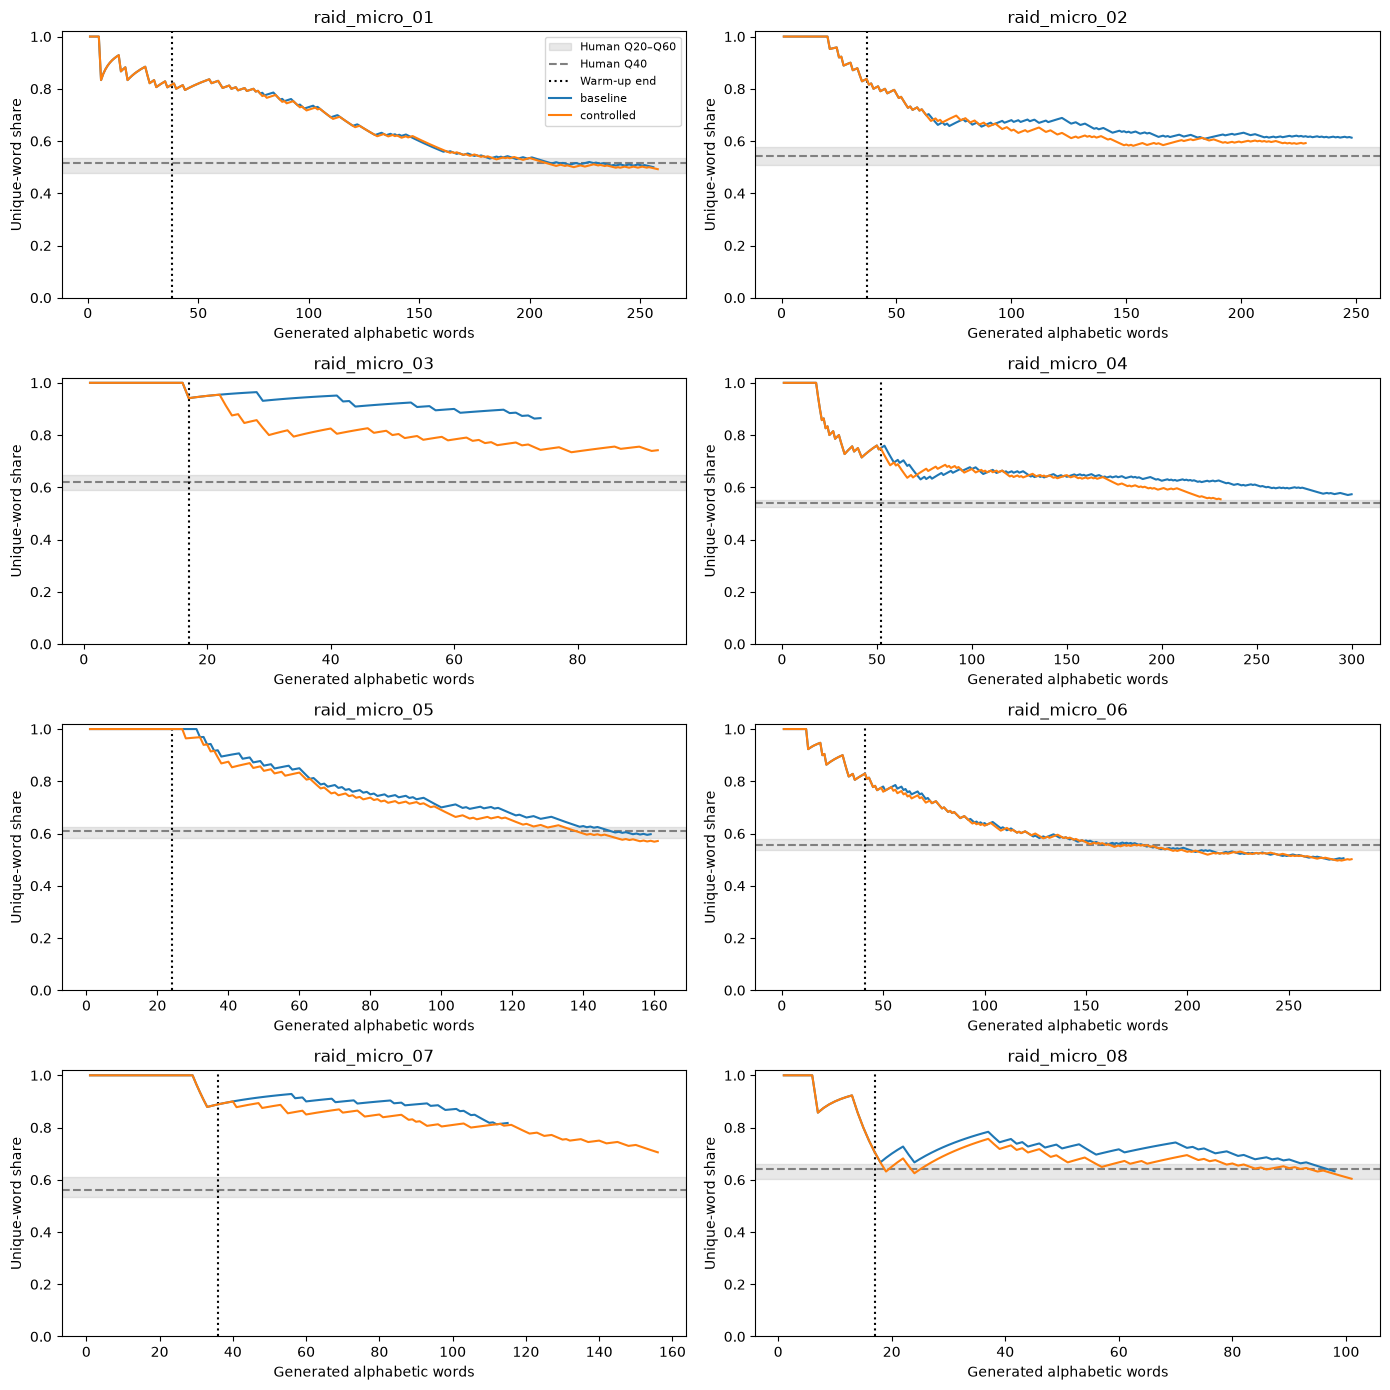

Completed-run target hits are feasibility outcomes for these eight cases, not an estimated population success rate.


In [8]:
rows=[]; reviews=[]; states={}
for c in cases:
    texts={}
    for condition in ('baseline','controlled'):
        path=OUT/c['case_id']/condition/'state.json'
        if not path.exists():
            rows.append(dict(case_id=c['case_id'],condition=condition,status='not_started',target_hit=None))
            continue
        payload=json.loads(path.read_text()); assert payload['contract_hash']==CONTRACT_HASH
        s=payload['state']; states[(c['case_id'],condition)]=s
        V,W=counts(s['committed_text']); k=V/W if W else np.nan
        assert W==len(s['words']) and V==len(set(s['words']))
        complete=s['finished'] and s['status']=='completed_eos'
        refs=c['refs']
        rows.append(dict(case_id=c['case_id'],condition=condition,status=s['status'],
            W_ref=c['W_ref'],W_generated=W,length_ratio=W/c['W_ref'],V=V,k=k,**refs,
            target_hit=bool(refs['H_h30']<=k<=refs['H_a10']) if complete and W else None,
            warmup_reached=W>=c['warmup_words'],search_attempts=s['search_attempts'],
            replacements=s['replacements'],fallbacks=s['fallbacks']))
        texts[condition]=s['committed_text']
    b=states.get((c['case_id'],'baseline')); t=states.get((c['case_id'],'controlled'))
    if b and t:
        n=min(c['warmup_words'],len(b['words']),len(t['words']))
        assert [x['word'] for x in b['trajectory'][:n]]==[x['word'] for x in t['trajectory'][:n]]
        assert all(x['action']=='ordinary' for x in t['trajectory'][:n])
    reviews.append(dict(case_id=c['case_id'],original=c['original'],**texts,
        meaning_preserved='',facts_names_numbers_preserved='',review_notes=''))
summary=pd.DataFrame(rows)
summary.to_csv(OUT/'generation_summary.csv',index=False)
# Preserve annotations if this reporting cell is re-run.
review_path=OUT/'manual_review.csv'
review_frame=pd.DataFrame(reviews)
if review_path.exists():
    prior_review=pd.read_csv(review_path,keep_default_na=False).set_index('case_id')
    for field in ('meaning_preserved','facts_names_numbers_preserved','review_notes'):
        review_frame[field]=review_frame.case_id.map(prior_review[field]).fillna('')
review_frame.to_csv(review_path,index=False)
write_json(OUT/'regenerated_texts.json',dict(contract_hash=CONTRACT_HASH,
    cases=[dict(case_id=c['case_id'],original=c['original'],
        outputs={condition:dict(text=states[(c['case_id'],condition)]['committed_text'],
            status=states[(c['case_id'],condition)]['status'])
            for condition in ('baseline','controlled') if (c['case_id'],condition) in states}) for c in cases]))
display(summary)
fig,axes=plt.subplots(4,2,figsize=(14,14),squeeze=False)
for ax,c in zip(axes.flat,cases):
    r=c['refs']; ax.axhspan(r['H_h30'],r['H_a10'],color='gray',alpha=.18,label='Human Q20–Q60')
    ax.axhline(r['H_h10'],color='gray',ls='--',label='Human Q40')
    ax.axvline(c['warmup_words'],color='black',ls=':',label='Warm-up end')
    for condition,color in [('baseline','tab:blue'),('controlled','tab:orange')]:
        s=states.get((c['case_id'],condition))
        if s and s['trajectory']:
            ax.plot([p['W_after'] for p in s['trajectory']], [p['k_after'] for p in s['trajectory']],
                color=color,label=condition+(' (incomplete)' if not s['finished'] else ''))
    ax.set(title=c['case_id'],xlabel='Generated alphabetic words',ylabel='Unique-word share',ylim=(0,1.02))
axes.flat[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT/'word_feedback_trajectories.png',dpi=180,bbox_inches='tight'); plt.show()
print('Completed-run target hits are feasibility outcomes for these eight cases, not an estimated population success rate.')

In [9]:
# Diagnose existing runs; no regeneration or model calls.
diagnostic_rows = []

for case in cases:
    state_path = OUT / case["case_id"] / "controlled" / "state.json"
    if not state_path.exists():
        continue

    payload = json.loads(state_path.read_text())
    assert payload["contract_hash"] == CONTRACT_HASH
    state = payload["state"]

    for step in state["trajectory"]:
        action = step["action"]
        searched = action in {"backtracked", "fallback_exhausted"}
        completed = int(step.get("completed_candidates", 0))

        diagnostic_rows.append({
            "case_id": case["case_id"],
            "mode": step["mode_before"],
            "word_index": step["word_index"],
            "original_word": step["original_word"],
            "chosen_word": step["word"],
            "action": action,
            "searched": searched,
            "replacement": action == "backtracked",
            "fallback": action == "fallback_exhausted",
            "fallback_no_completed_candidate": (
                action == "fallback_exhausted" and completed == 0
            ),
            "fallback_wrong_novelty_candidates": (
                action == "fallback_exhausted" and completed > 0
            ),
            "expanded_nodes": int(step.get("search_expanded", 0)),
            "completed_candidates": completed,
            "k_before": step["k_before"],
            "k_after": step["k_after"],
        })

diagnostics = pd.DataFrame(diagnostic_rows)
if diagnostics.empty:
    raise ValueError("No committed controlled-generation steps found.")

def summarize_modes(frame, groups):
    result = frame.groupby(groups, dropna=False).agg(
        generated_words=("action", "size"),
        searches=("searched", "sum"),
        replacements=("replacement", "sum"),
        fallbacks=("fallback", "sum"),
        fallbacks_no_completed_word=("fallback_no_completed_candidate", "sum"),
        fallbacks_wrong_novelty=("fallback_wrong_novelty_candidates", "sum"),
        expanded_nodes=("expanded_nodes", "sum"),
        completed_candidates=("completed_candidates", "sum"),
    ).reset_index()

    denominator = result["searches"].replace(0, np.nan)
    result["replacement_rate"] = result["replacements"] / denominator
    result["fallback_rate"] = result["fallbacks"] / denominator
    return result

by_mode = summarize_modes(diagnostics, ["mode"])
by_case_mode = summarize_modes(diagnostics, ["case_id", "mode"])

print("All cases — rates are descriptive, per search:")
display(by_mode.round(4))

print("Per case and mode:")
display(by_case_mode.round(4))

print("Accepted interventions:")
display(
    diagnostics.loc[
        diagnostics["replacement"],
        [
            "case_id", "mode", "word_index",
            "original_word", "chosen_word",
            "k_before", "k_after",
            "expanded_nodes", "completed_candidates",
        ],
    ].reset_index(drop=True)
)

diagnostics.to_csv(OUT / "controller_word_diagnostics.csv", index=False)
by_mode.to_csv(OUT / "controller_diagnostics_by_mode.csv", index=False)
by_case_mode.to_csv(
    OUT / "controller_diagnostics_by_case_mode.csv", index=False
)

print(
    "\nFallback interpretation:\n"
    "• No completed word: search exhausted without reaching a candidate word.\n"
    "• Wrong novelty: completed candidates existed, but none had the requested "
    "novel/repeated status.\n"
    "\nThe current logs do not distinguish low-probability word tokens from "
    "low-probability delimiters, prefix conflicts, or EOS-only branches. "
    "That requires instrumentation during a subsequent run.\n"
    "Only searches attached to committed words are counted here; interrupted "
    "search attempts are excluded."
)

All cases — rates are descriptive, per search:


,mode,generated_words,searches,replacements,fallbacks,fallbacks_no_completed_word,fallbacks_wrong_novelty,expanded_nodes,completed_candidates,replacement_rate,fallback_rate
0,decrease,1032,643,90,553,0,553,2227,2206,0.1400,0.8600
1,increase,99,57,1,56,0,56,119,60,0.0175,0.9825
2,normal,378,0,0,0,0,0,0,0,NaN,NaN


Per case and mode:


,case_id,mode,generated_words,searches,replacements,fallbacks,fallbacks_no_completed_word,fallbacks_wrong_novelty,expanded_nodes,completed_candidates,replacement_rate,fallback_rate
0,raid_micro_01,decrease,169,79,3,76,0,76,199,111,0.0380,0.9620
1,raid_micro_01,normal,89,0,0,0,0,0,0,0,NaN,NaN
2,raid_micro_02,decrease,191,121,17,104,0,104,388,231,0.1405,0.8595
3,raid_micro_02,normal,37,0,0,0,0,0,0,0,NaN,NaN
4,raid_micro_03,decrease,76,63,10,53,0,53,269,357,0.1587,0.8413
5,raid_micro_03,normal,17,0,0,0,0,0,0,0,NaN,NaN
6,raid_micro_04,decrease,179,111,22,89,0,89,379,411,0.1982,0.8018
7,raid_micro_04,normal,52,0,0,0,0,0,0,0,NaN,NaN
8,raid_micro_05,decrease,114,63,3,60,0,60,158,115,0.0476,0.9524
9,raid_micro_05,increase,11,6,0,6,0,6,12,6,0.0000,1.0000


Accepted interventions:


,case_id,mode,word_index,original_word,chosen_word,k_before,k_after,expanded_nodes,completed_candidates
0,raid_micro_01,decrease,79,package,the,0.782051,0.772152,3,2
1,raid_micro_01,decrease,142,browned,it,0.617021,0.612676,4,2
2,raid_micro_01,decrease,204,done,cooked,0.527094,0.524510,4,2
3,raid_micro_02,decrease,64,Commonwealth,Philippines,0.698413,0.687500,4,2
4,raid_micro_02,decrease,78,one,a,0.688312,0.679487,3,2
...,...,...,...,...,...,...,...,...,...
86,raid_micro_08,decrease,48,paper,report,0.702128,0.687500,3,2
87,raid_micro_08,decrease,50,a,an,0.693878,0.680000,3,3
88,raid_micro_08,decrease,65,it,the,0.671875,0.661538,4,4
89,raid_micro_08,decrease,81,Overall,In,0.662500,0.654321,4,3



Fallback interpretation:
• No completed word: search exhausted without reaching a candidate word.
• Wrong novelty: completed candidates existed, but none had the requested novel/repeated status.

The current logs do not distinguish low-probability word tokens from low-probability delimiters, prefix conflicts, or EOS-only branches. That requires instrumentation during a subsequent run.
Only searches attached to committed words are counted here; interrupted search attempts are excluded.


AI score: lower = more human-like to this frozen detector.
Negative score changes indicate a reduction in AI score.


,original,baseline,controlled,controlled_minus_baseline,controlled_minus_original
case_id,,,,,
raid_micro_01,0.649867,0.687626,0.675293,-0.012333,0.025426
raid_micro_02,0.651501,0.572330,0.621345,0.049015,-0.030156
raid_micro_03,0.660483,0.702749,0.597343,-0.105406,-0.063140
raid_micro_04,0.660908,0.673229,0.663860,-0.009369,0.002952
raid_micro_05,0.590246,0.609352,0.555498,-0.053854,-0.034748
raid_micro_06,0.590607,0.595183,0.617120,0.021936,0.026513
raid_micro_07,0.591105,0.613333,0.546113,-0.067220,-0.044992
raid_micro_08,0.593705,0.550241,0.580946,0.030705,-0.012759


Descriptive summaries across the eight cases:


,mean_AI_score,median_AI_score,mean_word_count
condition,,,
original,0.623553,0.621786,215.125
baseline,0.625505,0.611343,190.875
controlled,0.607190,0.607231,188.625


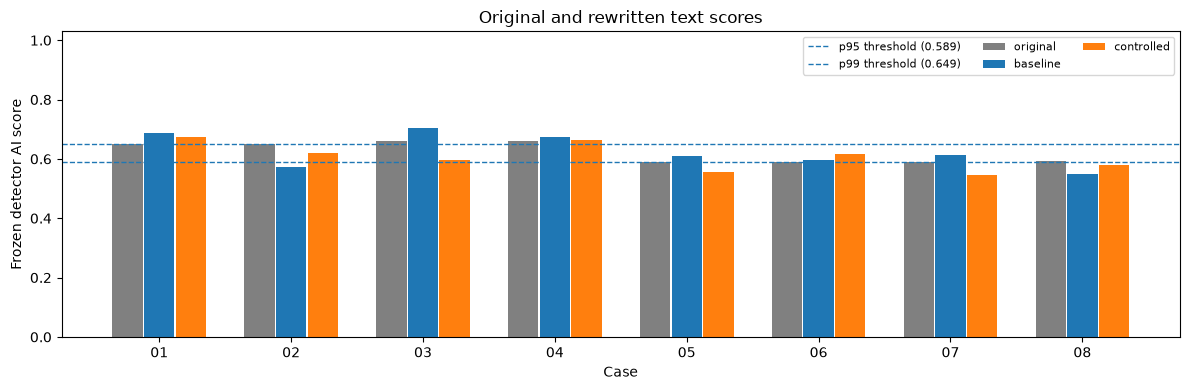

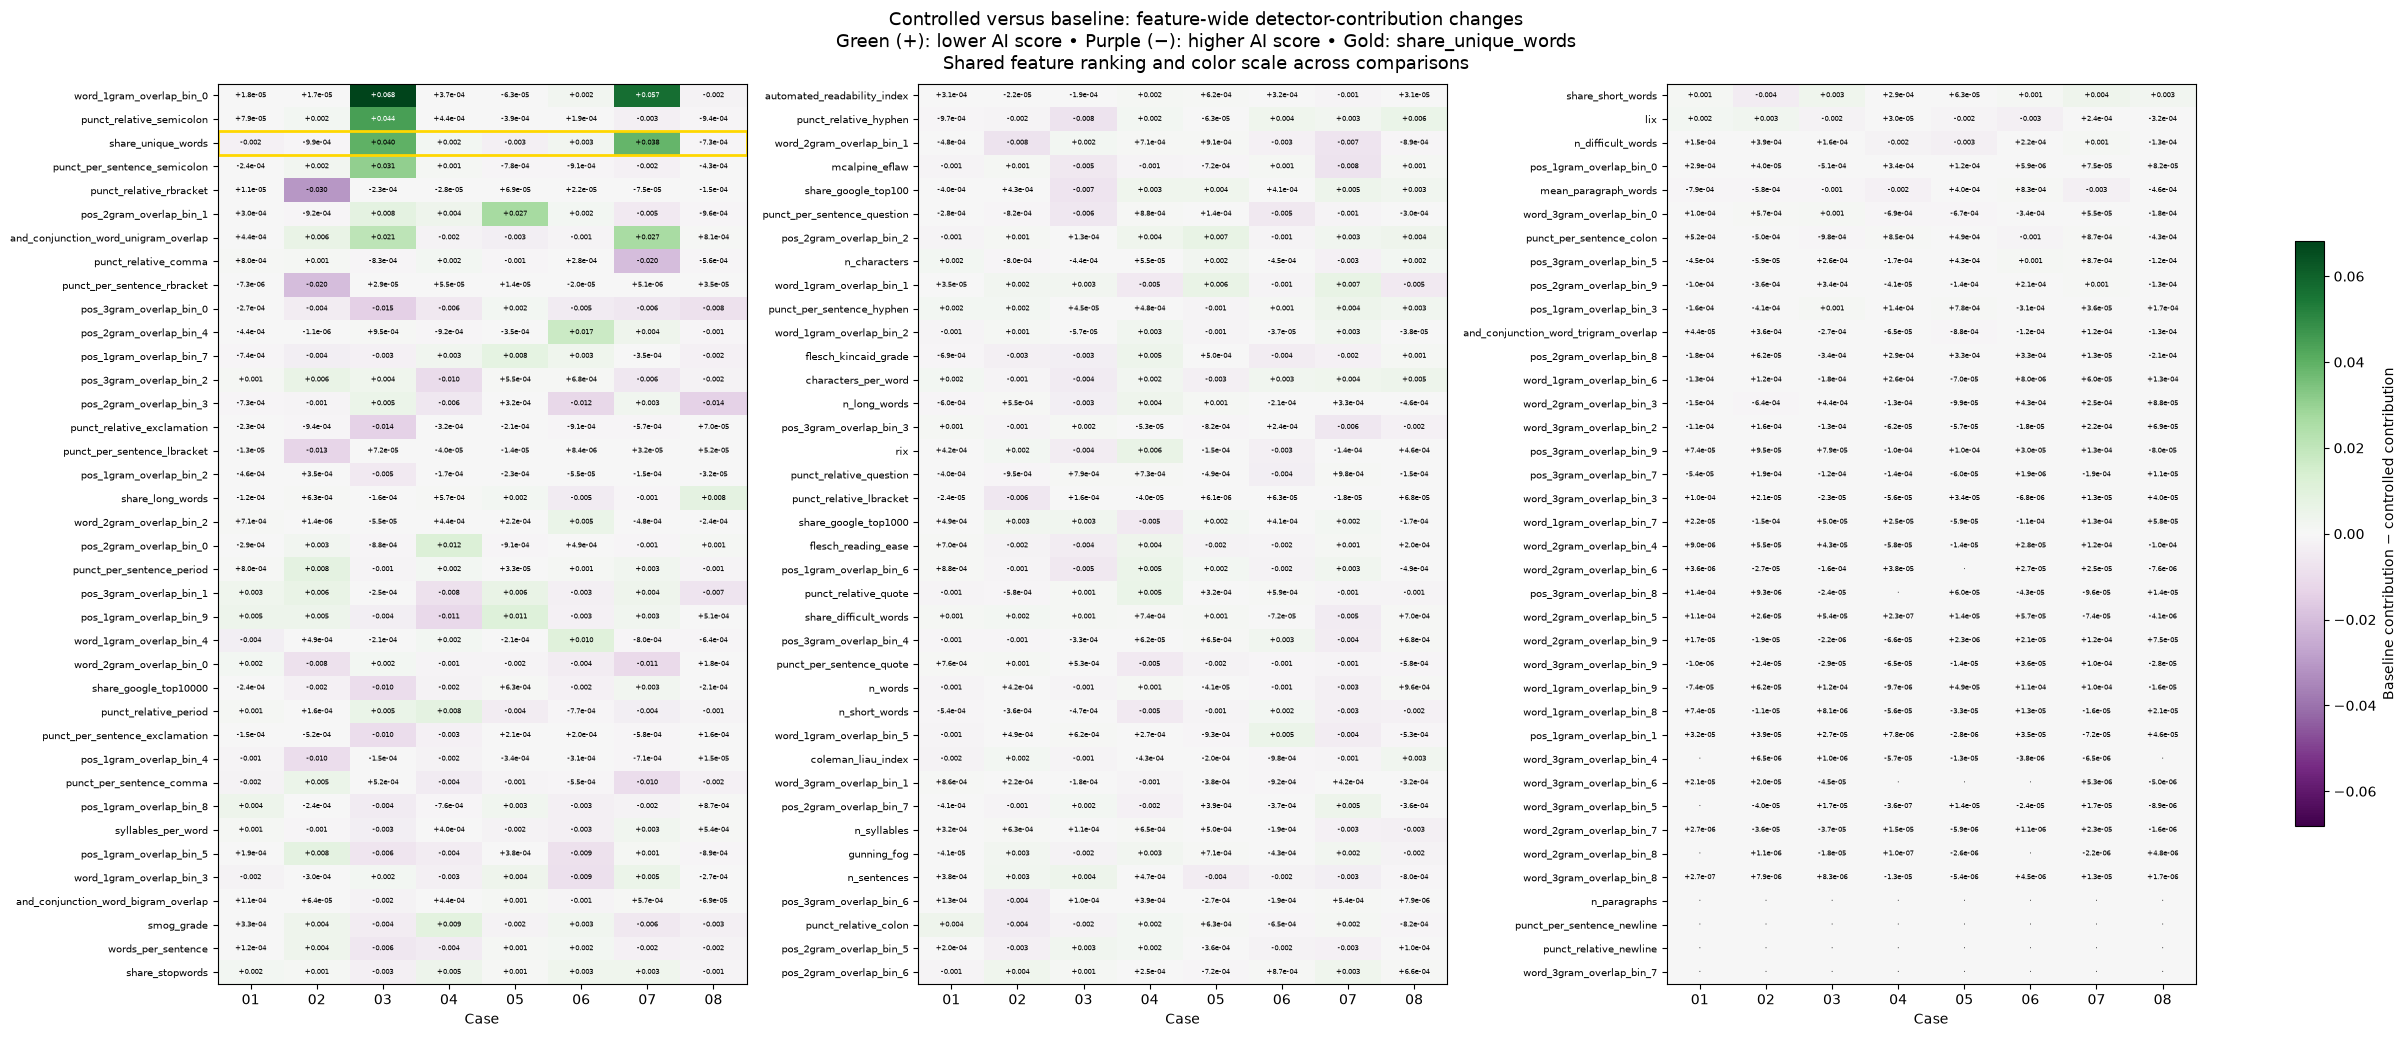

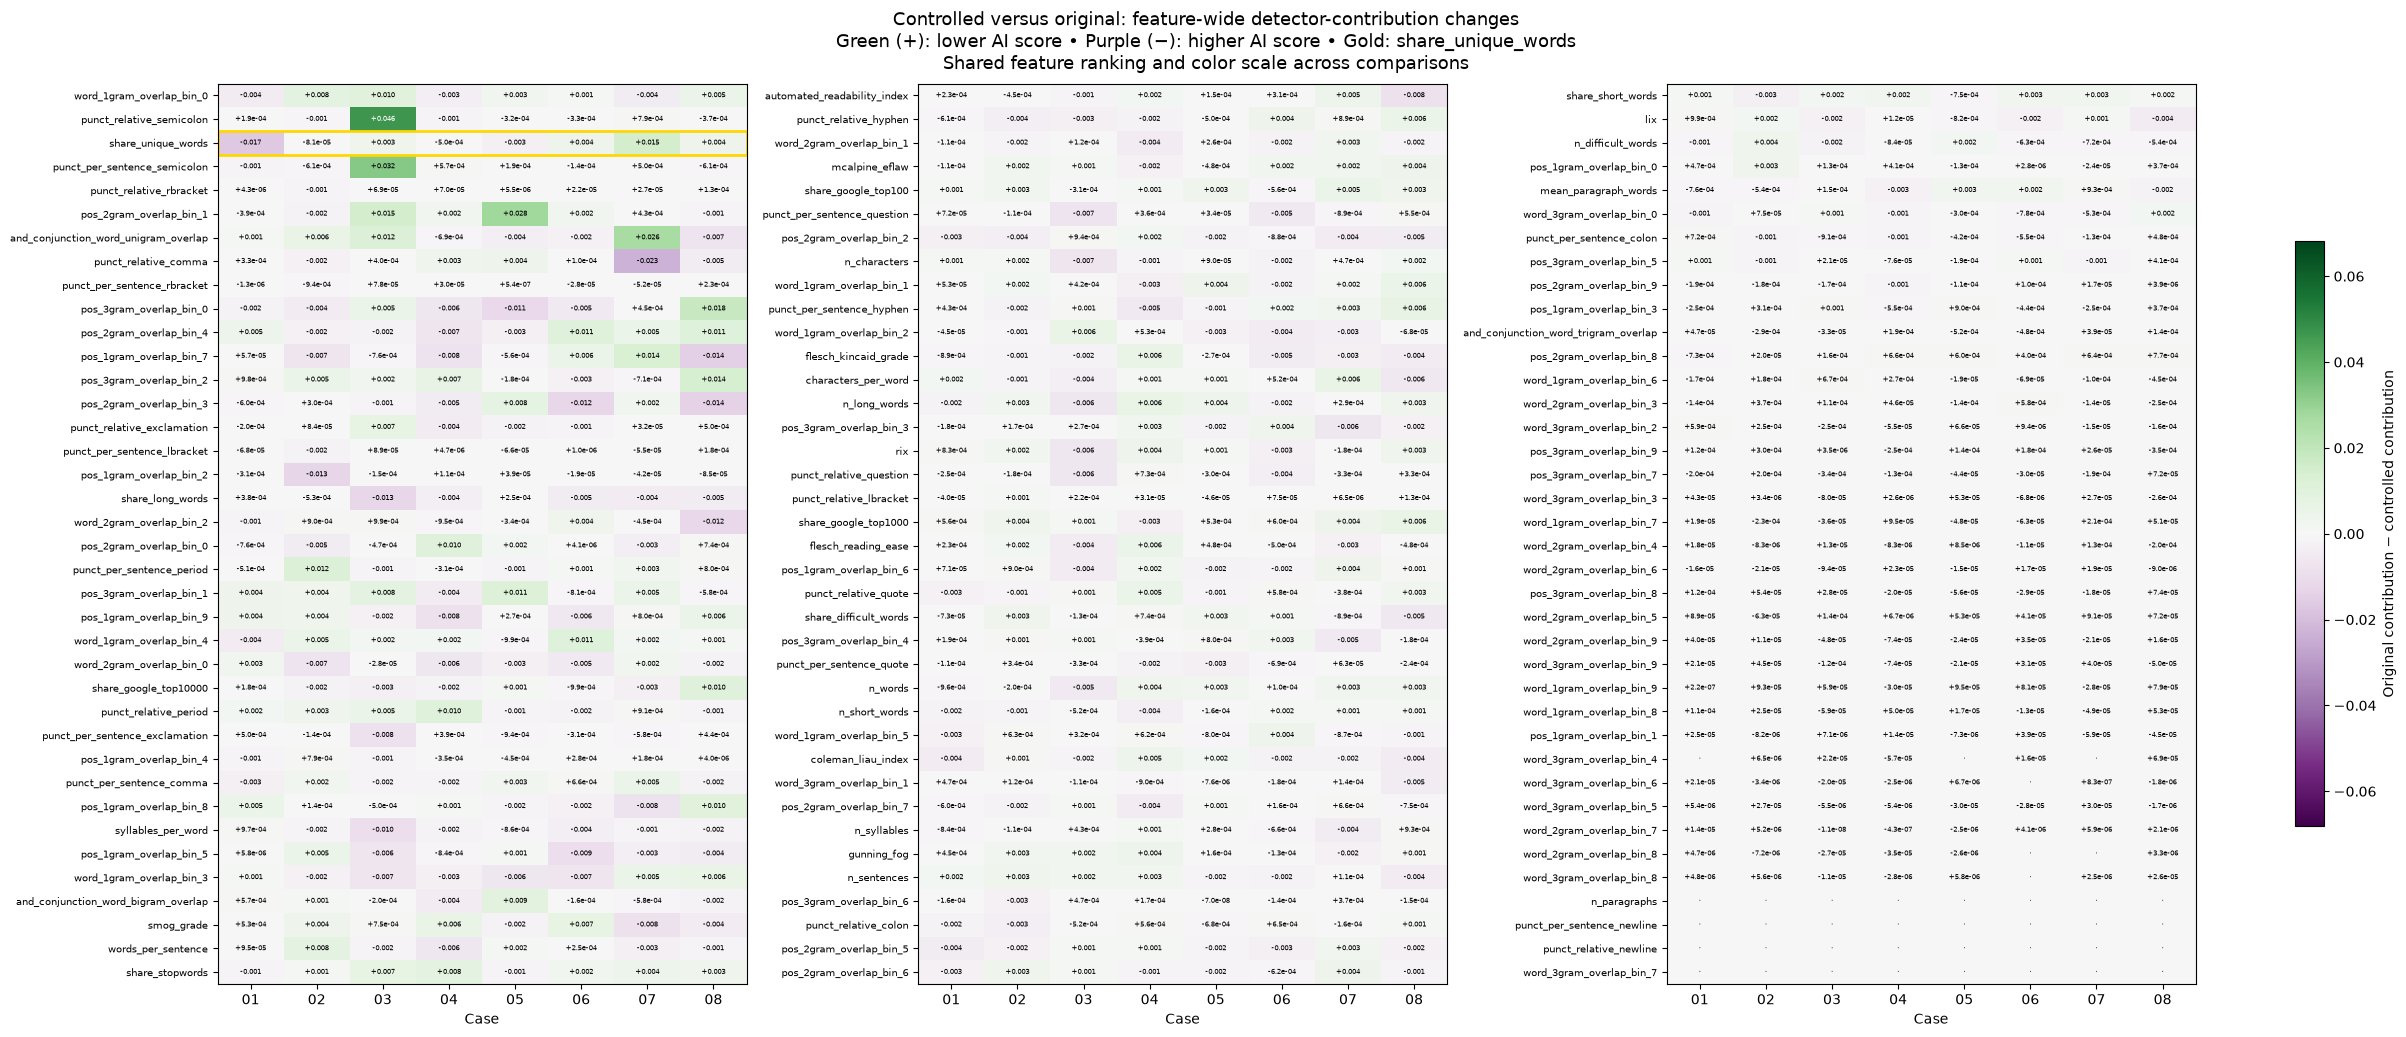

Scores, feature values, contribution changes, and figures saved in: ../results/causal/C02g_word_feedback_regeneration


In [10]:
import ast
import pickle
import re
from collections import Counter
from pathlib import Path

import textstat
from matplotlib.patches import Rectangle

# Set explicitly if your C02e2 notebook is outside the reproduction directory.
EXTRACTOR_NOTEBOOK = None

# Load the original extractor definitions without executing the notebook.
if EXTRACTOR_NOTEBOOK is None:
    candidates = sorted(ROOT.rglob("C02e2*.ipynb"))
    candidates = [p for p in candidates if ".ipynb_checkpoints" not in p.parts]
    if not candidates:
        raise FileNotFoundError(
            "Set EXTRACTOR_NOTEBOOK to the full path of your C02e2 notebook."
        )
else:
    candidates = [Path(EXTRACTOR_NOTEBOOK)]

extractor_source = None
for notebook_path in candidates:
    notebook = json.loads(notebook_path.read_text())
    for cell in notebook["cells"]:
        source = "".join(cell.get("source", []))
        if cell["cell_type"] == "code" and "def extract_fz118(" in source:
            extractor_source = source
            break
    if extractor_source is not None:
        break

if extractor_source is None:
    raise RuntimeError("Could not find extract_fz118 in the selected notebook.")

google_path = BASE / "google-10000-english.txt"
google_words = [
    line.strip().lower()
    for line in google_path.read_text().splitlines()
    if line.strip()
]
punctuation = [
    ("comma", ","), ("period", "."), ("colon", ":"), ("semicolon", ";"),
    ("question", "?"), ("exclamation", "!"), ("hyphen", "-"),
    ("quote", '"'), ("lparen", "("), ("rparen", ")"),
    ("lbracket", "["), ("rbracket", "]"), ("newline", "\n"),
]
extractor_namespace = {
    "np": np, "re": re, "Counter": Counter,
    "nlp": nlp, "textstat": textstat,
    "PUNCTUATION": punctuation,
    "GOOGLE_TOP": {
        n: set(google_words[:n]) for n in (100, 1000, 10000)
    },
}

# Execute function definitions only, in an isolated namespace.
tree = ast.parse(extractor_source)
definitions = ast.Module(
    body=[node for node in tree.body if isinstance(node, ast.FunctionDef)],
    type_ignores=[],
)
exec(compile(definitions, str(notebook_path), "exec"), extractor_namespace)
extract_for_scores = extractor_namespace["extract_fz118"]

feature_names = json.loads(
    (BASE / "fz118_feature_contract.json").read_text()
)["feature_names"]
model_features = json.loads(
    (PRIOR / "fz118_raid_model_features.json").read_text()
)
with (PRIOR / "fz118_raid_no_parentheses_detector.pkl").open("rb") as f:
    frozen_detector = pickle.load(f)

assert list(frozen_detector.classes_) == [0, 1]
assert set(model_features).issubset(feature_names)

def score_vector(text):
    normalized = str(text).translate(str.maketrans({"\n": " ", "\r": " "}))
    return extract_for_scores(normalized)

# Verify extractor compatibility against cached original features.
cached_features = pd.read_parquet(
    BASE / "fz118_paired_features.parquet"
).set_index("source_id")

records = []
vectors = []
for case in cases:
    original_vector = score_vector(case["original"])
    cached_vector = cached_features.loc[
        case["source_id"], feature_names
    ].to_numpy(dtype=float)

    if not np.allclose(original_vector, cached_vector, atol=1e-9, rtol=0):
        mismatch = np.flatnonzero(
            ~np.isclose(original_vector, cached_vector, atol=1e-9, rtol=0)
        )
        raise AssertionError(
            f"Extractor mismatch for {case['case_id']}: "
            f"{[feature_names[j] for j in mismatch]}. "
            "Resolve environment/extractor differences before scoring."
        )

    versions_to_score = [("original", case["original"], original_vector)]
    for condition in ("baseline", "controlled"):
        path = OUT / case["case_id"] / condition / "state.json"
        payload = json.loads(path.read_text())
        assert payload["contract_hash"] == CONTRACT_HASH
        state = payload["state"]
        if not state["finished"] or state["status"] != "completed_eos":
            raise RuntimeError(
                f"{case['case_id']} / {condition} is incomplete."
            )
        text = state["committed_text"]
        versions_to_score.append((condition, text, score_vector(text)))

    for condition, text, vector in versions_to_score:
        V, W = counts(text)
        records.append({
            "case_id": case["case_id"],
            "condition": condition,
            "W": W,
            "share_unique_words": V / W if W else np.nan,
        })
        vectors.append(vector)

raw_features = pd.DataFrame(vectors, columns=feature_names)
X = raw_features[model_features]
ai_scores = frozen_detector.predict_proba(X)[:, 1]

# Exact additive tree-path attribution, matching the earlier heatmap method.
# This is a descriptive decomposition, not a causal feature-effect estimate.
def path_contributions(forest, frame):
    values = frame.to_numpy(dtype=np.float32)
    contributions = np.zeros(values.shape, dtype=float)
    bias = 0.0

    for estimator in forest.estimators_:
        tree = estimator.tree_
        node_values = tree.value[:, 0, :]
        node_prob = node_values[:, 1] / node_values.sum(axis=1)
        bias += node_prob[0]

        for row in range(len(values)):
            node = 0
            while tree.feature[node] >= 0:
                feature = tree.feature[node]
                child = (
                    tree.children_left[node]
                    if values[row, feature] <= tree.threshold[node]
                    else tree.children_right[node]
                )
                contributions[row, feature] += node_prob[child] - node_prob[node]
                node = child

    contributions /= len(forest.estimators_)
    bias /= len(forest.estimators_)
    np.testing.assert_allclose(
        bias + contributions.sum(axis=1),
        forest.predict_proba(frame)[:, 1],
        atol=1e-9, rtol=0,
    )
    return contributions

contributions = path_contributions(frozen_detector, X)
score_table = pd.DataFrame(records)
score_table["AI_score"] = ai_scores
score_table["human_class_score"] = 1 - ai_scores

case_order = [c["case_id"] for c in cases]
wide = score_table.pivot(
    index="case_id", columns="condition", values="AI_score"
).reindex(case_order)[["original", "baseline", "controlled"]]
wide.columns.name = None
wide["controlled_minus_baseline"] = wide["controlled"] - wide["baseline"]
wide["controlled_minus_original"] = wide["controlled"] - wide["original"]

print("AI score: lower = more human-like to this frozen detector.")
print("Negative score changes indicate a reduction in AI score.")
display(wide.round(6))

print("Descriptive summaries across the eight cases:")
display(
    score_table.groupby("condition").agg(
        mean_AI_score=("AI_score", "mean"),
        median_AI_score=("AI_score", "median"),
        mean_word_count=("W", "mean"),
    ).reindex(["original", "baseline", "controlled"]).round(6)
)

ops = pd.read_csv(PRIOR / "raid_operating_points_p95_p99.csv")
fig, ax = plt.subplots(figsize=(12, 4))
positions = np.arange(len(case_order))
for condition, offset, color in [
    ("original", -.24, "gray"),
    ("baseline", 0, "tab:blue"),
    ("controlled", .24, "tab:orange"),
]:
    ax.bar(
        positions + offset, wide[condition], width=.23,
        color=color, label=condition,
    )
for op in ops.itertuples():
    threshold = float(op.validation_human_threshold)
    name = f"p{round(op.human_specificity_target * 100)}"
    ax.axhline(
        threshold, linestyle="--", linewidth=1,
        label=f"{name} threshold ({threshold:.3f})",
    )
ax.set(
    xticks=positions,
    xticklabels=[c.replace("raid_micro_", "") for c in case_order],
    xlabel="Case", ylabel="Frozen detector AI score", ylim=(0, 1.03),
    title="Original and rewritten text scores",
)
ax.legend(fontsize=8, ncol=3)
fig.tight_layout()
fig.savefig(OUT / "rewrite_detector_scores.png", dpi=180)
plt.show()

# Index contributions by case and condition.
contribution_frame = pd.DataFrame(contributions, columns=model_features)
contribution_frame.index = pd.MultiIndex.from_frame(
    score_table[["case_id", "condition"]]
)

comparisons = {}
for reference in ("baseline", "original"):
    before = contribution_frame.xs(reference, level="condition").reindex(case_order)
    after = contribution_frame.xs("controlled", level="condition").reindex(case_order)

    # Positive means contribution moved toward a lower AI score.
    movement = before - after
    np.testing.assert_allclose(
        movement.sum(axis=1),
        wide[reference] - wide["controlled"],
        atol=1e-9, rtol=0,
    )
    comparisons[reference] = movement.T

# Same feature order and color scale across both comparisons.
importance = pd.concat(
    [m.abs() for m in comparisons.values()], axis=1
).max(axis=1)
feature_order = importance.sort_values(ascending=False).index.tolist()
color_limit = max(float(importance.max()), 1e-8)

for reference, movement in comparisons.items():
    blocks = np.array_split(np.array(feature_order, dtype=object), 3)
    height = max(9, max(map(len, blocks)) * .27)
    fig, axes = plt.subplots(1, 3, figsize=(24, height), layout="constrained")

    for ax, block in zip(axes, blocks):
        data = movement.loc[list(block), case_order]
        image = ax.imshow(
            data.to_numpy(), cmap="PRGn",
            vmin=-color_limit, vmax=color_limit, aspect="auto",
        )
        ax.set_xticks(range(len(case_order)))
        ax.set_xticklabels([c.replace("raid_micro_", "") for c in case_order])
        ax.set_yticks(range(len(block)))
        ax.set_yticklabels(block, fontsize=7)
        ax.set_xlabel("Case")

        for row, feature in enumerate(block):
            if feature == "share_unique_words":
                ax.add_patch(Rectangle(
                    (-.5, row-.5), len(case_order), 1,
                    fill=False, edgecolor="gold", linewidth=2,
                ))
            for col, value in enumerate(data.iloc[row]):
                label = (
                    "·" if abs(value) < 1e-9
                    else f"{value:+.3f}" if abs(value) >= .001
                    else f"{value:+.1e}"
                )
                ax.text(
                    col, row, label, ha="center", va="center", fontsize=5,
                    color="white" if abs(value) > .6 * color_limit else "black",
                )

    fig.suptitle(
        f"Controlled versus {reference}: feature-wide detector-contribution changes\n"
        "Green (+): lower AI score • Purple (−): higher AI score • "
        "Gold: share_unique_words\n"
        "Shared feature ranking and color scale across comparisons",
        fontsize=13,
    )
    fig.colorbar(
        image, ax=list(axes), shrink=.65,
        label=f"{reference.capitalize()} contribution − controlled contribution",
    )
    fig.savefig(
        OUT / f"heatmap_controlled_vs_{reference}.png",
        dpi=200, bbox_inches="tight",
    )
    plt.show()
    movement.to_csv(OUT / f"contribution_movement_vs_{reference}.csv")

score_table.to_csv(OUT / "rewrite_detector_scores.csv", index=False)
wide.to_csv(OUT / "rewrite_detector_score_comparison.csv")
pd.concat(
    [score_table[["case_id", "condition"]], raw_features], axis=1
).to_csv(OUT / "rewrite_detector_features.csv", index=False)

print("Scores, feature values, contribution changes, and figures saved in:", OUT)